# OCT corrected same-patient leakage audit — one-run notebook

**Purpose.** Re-run the Kermany OCT binary disease-vs-normal experiment with a corrected paired design that:

1. never trains on an exact test image;
2. evaluates the rigorous and controlled-leakage arms on the **same test images**;
3. keeps the rigorous training set patient-disjoint from the test set;
4. introduces only *other images from the same test patients* into the controlled-leakage arm;
5. matches training-set size and class counts between arms by same-class swaps;
6. uses an identical patient-disjoint validation set for early stopping in both arms, so the test set is never used for model selection;
7. records an explicit leakage audit for every fold;
8. reports paired **patient-cluster bootstrap confidence intervals** and cluster-level paired randomization tests.

This notebook does **not** force a positive leakage effect. For OCT, a small or null delta is scientifically plausible because the task can be near ceiling. The integrity assertions—not a particular accuracy—define a successful run.

### Methodological basis

- Kermany's dataset documentation states that filenames encode `(disease)-(randomized patient ID)-(image number)`; patient ID is therefore used as the grouping variable.
- Tampu et al. showed that subject overlap can substantially inflate OCT results and explicitly audited Kermany subject IDs.
- CLAIM 2024 recommends that medical-image partitions normally be disjoint at the patient level or higher and that the partition level be reported explicitly.
- Cluster bootstrap is appropriate for correlated diagnostic observations from the same patient.

References: Kermany et al., *Cell* 2018, DOI `10.1016/j.cell.2018.02.010`; Tampu et al., *Scientific Reports* 2022, PMCID `PMC9500039`; CLAIM 2024, DOI `10.1148/ryai.240300`; Rutter, *Academic Radiology* 2000, DOI `10.1016/S1076-6332(00)80381-5`.


In [1]:
# =========================
# 1. Configuration
# =========================
from pathlib import Path
import os, re, sys, json, math, time, random, hashlib, shutil, zipfile, platform, warnings
warnings.filterwarnings('ignore')

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
FOLDS = 5
VAL_FOLDS = 5              # one SGKF fold = ~20% of safe training pool for model selection
EPOCHS = 12
PATIENCE = 3
LR = 1e-4
WEIGHT_DECAY = 1e-4
MAX_IMAGES_PER_CLASS = 600 # preserves the submitted study's 1,200-image balanced primary cohort
LEAK_FRACTION = 1.0        # use all eligible same-patient sibling rows, then same-class swap to size-match
BOOTSTRAPS = 2000
PERMUTATIONS = 2000
RUN_ARCHITECTURES = ['ResNet50', 'ConvNeXtTiny']
FAST_DEV_RUN = False       # True -> 2 folds, 1 epoch, 80/class; ONLY for pipeline debugging
DATA_ROOT_OVERRIDE = None  # e.g. '/kaggle/input/kermany2018/OCT2017 '
PRETRAINED = True

if FAST_DEV_RUN:
    FOLDS = 2; VAL_FOLDS = 2; EPOCHS = 1; PATIENCE = 1; MAX_IMAGES_PER_CLASS = 80
    BOOTSTRAPS = 200; PERMUTATIONS = 200

BASE = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/content') if Path('/content').exists() else Path.cwd()
OUT = BASE / 'oct_corrected_leakage_audit'
PRED_DIR = OUT / 'predictions'
SPLIT_DIR = OUT / 'splits'
FIG_DIR = OUT / 'figures'
for p in [OUT, PRED_DIR, SPLIT_DIR, FIG_DIR]: p.mkdir(parents=True, exist_ok=True)

print('Output:', OUT)
print('FAST_DEV_RUN:', FAST_DEV_RUN)


Output: /kaggle/working/oct_corrected_leakage_audit
FAST_DEV_RUN: False


In [2]:
# =========================
# 2. Imports, versions, reproducibility, GPU + pretrained-weight preflight
# =========================
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
import torchvision.models as tvm

import sklearn
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, recall_score,
    brier_score_loss, log_loss
)

import scipy
from scipy.stats import spearmanr

print('Python      :', platform.python_version())
print('torch       :', torch.__version__)
print('torchvision :', torchvision.__version__)
print('sklearn     :', sklearn.__version__)
print('scipy       :', scipy.__version__)


def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False

seed_everything()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    # Fail immediately on an incompatible CUDA build instead of after training starts.
    _probe = nn.Conv2d(3, 4, 3).to(DEVICE)
    _probe(torch.randn(1, 3, 16, 16, device=DEVICE)).sum().backward()
    del _probe; torch.cuda.empty_cache()
else:
    print('WARNING: CPU execution will be very slow. A Kaggle/Colab GPU is strongly recommended.')

# Preflight the exact pretrained weights before any fold starts.
def _make_resnet50():
    w = tvm.ResNet50_Weights.DEFAULT if PRETRAINED else None
    m = tvm.resnet50(weights=w)
    m.fc = nn.Linear(m.fc.in_features, 2)
    return m

def _make_convnext_tiny():
    w = tvm.ConvNeXt_Tiny_Weights.DEFAULT if PRETRAINED else None
    m = tvm.convnext_tiny(weights=w)
    m.classifier[2] = nn.Linear(m.classifier[2].in_features, 2)
    return m

MODEL_FACTORIES = {'ResNet50': _make_resnet50, 'ConvNeXtTiny': _make_convnext_tiny}

try:
    for _name in RUN_ARCHITECTURES:
        _m = MODEL_FACTORIES[_name]()
        del _m
    print('Pretrained-weight preflight: PASSED')
except Exception as e:
    raise RuntimeError(
        'Could not initialize ImageNet pretrained weights. On Kaggle, enable Internet for the first run '
        'or attach/cache the torchvision weights. The notebook intentionally does not silently fall back '
        'to random initialization because that would change the experiment. Original error: '+repr(e)
    )


Python      : 3.13.15
torch       : 2.11.0+cu128
torchvision : 0.26.0+cu128
sklearn     : 1.6.1
scipy       : 1.16.3
Device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 235MB/s]


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 198MB/s] 


Pretrained-weight preflight: PASSED


In [3]:
# =========================
# 3. Robust Kermany OCT root discovery + indexing + de-duplication
# =========================
CLASSES = {'CNV', 'DME', 'DRUSEN', 'NORMAL'}
IMG_EXTS = {'.jpeg', '.jpg', '.png'}
FNAME_RE = re.compile(r'^(CNV|DME|DRUSEN|NORMAL)-([^-]+)-(.+?)\.(jpeg|jpg|png)$', re.I)


def candidate_oct_roots(search_base):
    search_base = Path(search_base)
    cands = []
    if not search_base.exists(): return cands
    # OCT root is identified by train/test children whose class dirs contain the four Kermany labels.
    for p in search_base.rglob('*'):
        if not p.is_dir(): continue
        try:
            children = {x.name.strip().lower(): x for x in p.iterdir() if x.is_dir()}
        except PermissionError:
            continue
        if not {'train','test'}.issubset(children):
            continue
        tr = children['train']
        tr_classes = {x.name.strip().upper() for x in tr.iterdir() if x.is_dir()}
        if CLASSES.issubset(tr_classes):
            # lightweight score from file counts under class folders
            n = sum(1 for x in p.rglob('*') if x.is_file() and x.suffix.lower() in IMG_EXTS and FNAME_RE.match(x.name))
            cands.append((n, p))
    return sorted(cands, key=lambda z: (-z[0], len(str(z[1]))))


def resolve_oct_root():
    if DATA_ROOT_OVERRIDE:
        p = Path(DATA_ROOT_OVERRIDE)
        if not p.exists(): raise FileNotFoundError(f'DATA_ROOT_OVERRIDE does not exist: {p}')
        return p
    bases = [Path('/kaggle/input'), Path('/content'), Path.cwd()]
    allc = []
    for b in bases: allc.extend(candidate_oct_roots(b))
    # dedupe paths
    uniq=[]; seen=set()
    for n,p in allc:
        rp=str(p.resolve())
        if rp not in seen: uniq.append((n,p)); seen.add(rp)
    if not uniq:
        raise FileNotFoundError(
            'Kermany OCT root not found. On Kaggle attach the kermany2018 dataset. '
            'Expected a directory containing train/test and CNV,DME,DRUSEN,NORMAL class folders.'
        )
    print('Candidate OCT roots:')
    for n,p in uniq[:10]: print(f'  {n:>7,} images  {p}')
    chosen = uniq[0][1]
    print('Chosen root:', chosen)
    return chosen

ROOT = resolve_oct_root()

records=[]
for f in ROOT.rglob('*'):
    if not f.is_file() or f.suffix.lower() not in IMG_EXTS: continue
    m=FNAME_RE.match(f.name)
    if not m: continue
    disease=m.group(1).upper(); patient=m.group(2); image_no=m.group(3)
    # Capture source split only for audit; it is NOT used for model partitioning.
    parts=[x.strip().lower() for x in f.parts]
    source_split=next((s for s in ['train','val','test'] if s in parts), 'unknown')
    records.append({
        'filepath':str(f), 'Disease':disease, 'Patient_ID':str(patient), 'Image_No':str(image_no),
        'Label':0 if disease=='NORMAL' else 1, 'source_split':source_split,
        'sample_key':f'{disease}-{patient}-{image_no}'
    })

raw=pd.DataFrame(records)
if raw.empty: raise RuntimeError('No Kermany-format OCT files were indexed.')
print(f'Indexed raw rows: {len(raw):,}')

# If the same dataset is duplicated under the chosen root, keep one canonical sample key only.
dup_keys=int(raw.duplicated('sample_key').sum())
raw=raw.sort_values(['sample_key','filepath']).drop_duplicates('sample_key',keep='first').reset_index(drop=True)
print(f'Duplicate sample keys removed: {dup_keys:,}')
print(f'Unique images: {len(raw):,} | patients: {raw.Patient_ID.nunique():,}')
print(pd.crosstab(raw.source_split, raw.Disease))

# Filename patient identifier should behave like a subject/volume grouping key.
pt_label_n = raw.groupby('Patient_ID').Label.nunique()
print('Patients with both binary labels:', int((pt_label_n>1).sum()))


Candidate OCT roots:
   84,484 images  /kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 
   84,484 images  /kaggle/input/datasets/paultimothymooney/kermany2018/oct2017/OCT2017 
        0 images  /kaggle/input/datasets/paultimothymooney/kermany2018/oct2017/__MACOSX/OCT2017 
Chosen root: /kaggle/input/datasets/paultimothymooney/kermany2018/OCT2017 
Indexed raw rows: 84,484
Duplicate sample keys removed: 879
Unique images: 83,605 | patients: 4,657
Disease         CNV    DME  DRUSEN  NORMAL
source_split                              
test            242    242     242     242
train         36974  11178    8378   26102
val               0      2       0       3
Patients with both binary labels: 695


In [4]:
# =========================
# 4. Reproducible 1,200-image primary cohort + byte-hash audit
# =========================
def balanced_sample(df, n_per_class=MAX_IMAGES_PER_CLASS, seed=SEED):
    pos=df[df.Label==1]; neg=df[df.Label==0]
    k=min(n_per_class, len(pos), len(neg))
    if k < 2*FOLDS:
        raise RuntimeError(f'Not enough images per class for {FOLDS}-fold evaluation: {k}')
    out=pd.concat([
        pos.sample(k, random_state=seed),
        neg.sample(k, random_state=seed)
    ], ignore_index=True)
    return out.sample(frac=1, random_state=seed).reset_index(drop=True)

cohort=balanced_sample(raw)
cohort['row_id']=np.arange(len(cohort),dtype=int)
print(f'Cohort: {len(cohort)} images | {cohort.Patient_ID.nunique()} patients | prevalence={cohort.Label.mean():.3f}')
print(cohort.Disease.value_counts())

# SHA256 on only the analysis cohort: catches an exact image duplicated under another filename/path.
def sha256_file(path, chunk=1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as fh:
        while True:
            b=fh.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

hash_cache=OUT/'cohort_hashes.csv'
if hash_cache.exists():
    hc=pd.read_csv(hash_cache)
    expected=cohort[['row_id','sample_key']].sort_values('row_id').reset_index(drop=True)
    cached=hc[['row_id','sample_key']].sort_values('row_id').reset_index(drop=True) if {'row_id','sample_key'}.issubset(hc.columns) else None
    if cached is not None and cached.equals(expected):
        cohort=cohort.merge(hc[['row_id','sha256']],on='row_id',how='left')
    else:
        hash_cache.unlink()
if 'sha256' not in cohort.columns:
    print('Computing SHA256 for cohort (one-time exact-content audit)...')
    cohort['sha256']=[sha256_file(p) for p in cohort.filepath]
    cohort[['row_id','sample_key','sha256']].to_csv(hash_cache,index=False)

exact_dups=int(cohort.duplicated('sha256').sum())
print('Exact byte-duplicate images inside selected cohort:', exact_dups)
if exact_dups:
    # Keep one copy of exact duplicates so no hidden duplicate can cross a fold boundary.
    before=len(cohort)
    cohort=cohort.sort_values('row_id').drop_duplicates('sha256',keep='first').reset_index(drop=True)
    cohort['row_id']=np.arange(len(cohort),dtype=int)
    print(f'Removed {before-len(cohort)} exact duplicate(s); final cohort n={len(cohort)}')

cohort.to_csv(OUT/'cohort_manifest.csv',index=False)


Cohort: 1200 images | 855 patients | prevalence=0.500
Disease
NORMAL    600
CNV       406
DME       109
DRUSEN     85
Name: count, dtype: int64
Computing SHA256 for cohort (one-time exact-content audit)...
Exact byte-duplicate images inside selected cohort: 0


In [5]:
# =========================
# 5. Correct paired split builder
# =========================
def _safe_val_split(safe_df, fold_seed):
    """Patient-disjoint model-selection split from the non-test-patient safe pool."""
    n_groups=safe_df.Patient_ID.nunique()
    n_splits=min(VAL_FOLDS, n_groups)
    if n_splits < 2: raise RuntimeError('Not enough safe patient groups for a validation split.')
    # Try deterministic seeds until train and val both contain both classes.
    for off in range(20):
        sg=StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=fold_seed+off)
        tr_i, va_i=next(sg.split(safe_df, safe_df.Label, groups=safe_df.Patient_ID))
        tr=safe_df.iloc[tr_i].copy(); va=safe_df.iloc[va_i].copy()
        if tr.Label.nunique()==2 and va.Label.nunique()==2:
            return tr,va
    raise RuntimeError('Could not create a two-class patient-disjoint validation set.')


def _sample_n(df,n,seed):
    if n<=0: return df.iloc[0:0].copy()
    return df.sample(n=n, random_state=seed, replace=False)


def build_controlled_fold(df, train_idx, test_idx, fold):
    """
    Fixed image test fold -> two training arms.
    Rigorous: no test patient may occur in training.
    Controlled-leak: exact test images still forbidden, but other images from test patients are
    introduced by same-class swaps, keeping train size and class counts identical to rigorous.
    The same safe patient-disjoint validation set is used by both arms.
    """
    test=df.iloc[test_idx].copy().reset_index(drop=True)
    raw_train=df.iloc[train_idx].copy().reset_index(drop=True)

    # Hard exact-content exclusion regardless of filename/patient metadata.
    test_hashes=set(test.sha256)
    raw_train=raw_train[~raw_train.sha256.isin(test_hashes)].copy().reset_index(drop=True)
    test_patients=set(test.Patient_ID.astype(str))
    safe=raw_train[~raw_train.Patient_ID.astype(str).isin(test_patients)].copy().reset_index(drop=True)
    leak_candidates=raw_train[raw_train.Patient_ID.astype(str).isin(test_patients)].copy().reset_index(drop=True)

    rigorous_train, val=_safe_val_split(safe, SEED+1000*fold)
    rigorous_train=rigorous_train.reset_index(drop=True); val=val.reset_index(drop=True)

    rng_seed=SEED+10000*fold
    leak_parts=[]; remove_ids=[]
    for y in [0,1]:
        cand=leak_candidates[leak_candidates.Label==y]
        base=rigorous_train[rigorous_train.Label==y]
        n=int(round(len(cand)*LEAK_FRACTION))
        n=min(n, len(cand), max(len(base)-2,0))
        chosen=_sample_n(cand,n,rng_seed+10+y)
        removed=_sample_n(base,n,rng_seed+20+y)
        leak_parts.append(chosen)
        remove_ids.extend(removed.row_id.astype(int).tolist())

    leaky_train=rigorous_train[~rigorous_train.row_id.isin(remove_ids)].copy()
    if leak_parts: leaky_train=pd.concat([leaky_train]+leak_parts,ignore_index=True)
    leaky_train=leaky_train.sample(frac=1,random_state=rng_seed+99).reset_index(drop=True)

    # ---------- non-negotiable integrity assertions ----------
    def ids(x): return set(x.row_id.astype(int))
    def pats(x): return set(x.Patient_ID.astype(str))
    def hashes(x): return set(x.sha256.astype(str))
    assert ids(test).isdisjoint(ids(rigorous_train)) and ids(test).isdisjoint(ids(leaky_train))
    assert hashes(test).isdisjoint(hashes(rigorous_train)) and hashes(test).isdisjoint(hashes(leaky_train))
    assert pats(test).isdisjoint(pats(rigorous_train)), 'Rigorous train/test patient overlap detected'
    assert pats(test).isdisjoint(pats(val)), 'Validation/test patient overlap detected'
    assert pats(val).isdisjoint(pats(rigorous_train)), 'Rigorous train/validation patient overlap detected'
    assert pats(val).isdisjoint(pats(leaky_train)), 'Leaky train/validation patient overlap detected'
    assert len(rigorous_train)==len(leaky_train), 'Training sizes differ'
    assert rigorous_train.Label.value_counts().sort_index().to_dict()==leaky_train.Label.value_counts().sort_index().to_dict(), 'Training class counts differ'

    overlap_patients=pats(test)&pats(leaky_train)
    leak_counts=leaky_train.Patient_ID.astype(str).value_counts()
    same_label_counts=leaky_train.groupby(['Patient_ID','Label']).size()
    test['n_train_siblings']=test.Patient_ID.astype(str).map(leak_counts).fillna(0).astype(int)
    test['n_same_label_siblings']=[int(same_label_counts.get((str(p),int(y)),0)) for p,y in zip(test.Patient_ID,test.Label)]

    audit={
        'fold':fold,
        'test_n':len(test), 'test_patients':test.Patient_ID.nunique(),
        'rig_train_n':len(rigorous_train), 'leak_train_n':len(leaky_train), 'val_n':len(val),
        'rig_train_test_exact_overlap':len(ids(test)&ids(rigorous_train)),
        'leak_train_test_exact_overlap':len(ids(test)&ids(leaky_train)),
        'rig_train_test_hash_overlap':len(hashes(test)&hashes(rigorous_train)),
        'leak_train_test_hash_overlap':len(hashes(test)&hashes(leaky_train)),
        'rig_train_test_patient_overlap':len(pats(test)&pats(rigorous_train)),
        'leak_train_test_patient_overlap':len(overlap_patients),
        'test_images_exposed_to_sibling':int((test.n_train_siblings>0).sum()),
        'test_exposure_pct':float((test.n_train_siblings>0).mean()),
        'max_siblings_per_test_image':int(test.n_train_siblings.max()),
        'rig_class0':int((rigorous_train.Label==0).sum()), 'rig_class1':int((rigorous_train.Label==1).sum()),
        'leak_class0':int((leaky_train.Label==0).sum()), 'leak_class1':int((leaky_train.Label==1).sum()),
        'val_test_patient_overlap':len(pats(val)&pats(test)),
    }
    return rigorous_train, leaky_train, val, test, audit

# Unit test the split logic on synthetic metadata before touching the real images.
def split_self_test():
    rows=[]; rid=0
    for p in range(40):
        y=p%2
        for j in range(3):
            rows.append({'row_id':rid,'Patient_ID':str(p),'Label':y,'sha256':f'h{rid}','filepath':f'f{rid}','sample_key':f's{rid}'})
            rid+=1
    d=pd.DataFrame(rows)
    sk=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
    tr,te=next(sk.split(d,d.Label))
    a,b,v,t,au=build_controlled_fold(d,tr,te,1)
    assert au['rig_train_test_patient_overlap']==0
    assert au['leak_train_test_exact_overlap']==0
    assert au['leak_train_test_patient_overlap']>0
    assert len(a)==len(b)
    print('Synthetic split self-test: PASSED')

split_self_test()


Synthetic split self-test: PASSED


In [6]:
# =========================
# 6. Build and freeze all fold manifests + clean leakage audit
# =========================
outer=StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
FOLD_DATA={}; audit_rows=[]
seen_test=[]
for fold,(tr_idx,te_idx) in enumerate(outer.split(cohort,cohort.Label),1):
    rig,leak,val,test,audit=build_controlled_fold(cohort,tr_idx,te_idx,fold)
    FOLD_DATA[fold]={'rig':rig,'leak':leak,'val':val,'test':test}
    audit_rows.append(audit); seen_test.extend(test.row_id.astype(int).tolist())
    for role,frame in [('rig_train',rig),('leak_train',leak),('val',val),('test',test)]:
        x=frame.copy(); x['role']=role; x['fold']=fold
        x.to_csv(SPLIT_DIR/f'fold{fold}_{role}.csv',index=False)

# Every selected image must be tested exactly once because outer folds are image-stratified.
assert sorted(seen_test)==sorted(cohort.row_id.astype(int).tolist())
audit_df=pd.DataFrame(audit_rows)
audit_df.to_csv(OUT/'leakage_audit_by_fold.csv',index=False)
print(audit_df.to_string(index=False))

assert (audit_df.rig_train_test_exact_overlap==0).all()
assert (audit_df.leak_train_test_exact_overlap==0).all()
assert (audit_df.rig_train_test_hash_overlap==0).all()
assert (audit_df.leak_train_test_hash_overlap==0).all()
assert (audit_df.rig_train_test_patient_overlap==0).all()
assert (audit_df.val_test_patient_overlap==0).all()
assert (audit_df.rig_train_n==audit_df.leak_train_n).all()
assert (audit_df.rig_class0==audit_df.leak_class0).all() and (audit_df.rig_class1==audit_df.leak_class1).all()

print('\nCLEAN LEAKAGE AUDIT: PASSED')
print('Mean controlled-leak exposure among test images:', f'{100*audit_df.test_exposure_pct.mean():.1f}%')


 fold  test_n  test_patients  rig_train_n  leak_train_n  val_n  rig_train_test_exact_overlap  leak_train_test_exact_overlap  rig_train_test_hash_overlap  leak_train_test_hash_overlap  rig_train_test_patient_overlap  leak_train_test_patient_overlap  test_images_exposed_to_sibling  test_exposure_pct  max_siblings_per_test_image  rig_class0  rig_class1  leak_class0  leak_class1  val_test_patient_overlap
    1     240            218          652           652    167                             0                              0                            0                             0                               0                               78                              94           0.391667                            8         367         285          367          285                         0
    2     240            224          644           644    159                             0                              0                            0                             0          

In [7]:
# =========================
# 7. Data pipeline (manuscript-aligned augmentation; no test-time augmentation)
# =========================
IM_MEAN=(0.485,0.456,0.406); IM_STD=(0.229,0.224,0.225)
TRAIN_TF=T.Compose([
    T.Resize((IMG_SIZE,IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05,0.05)),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.ToTensor(), T.Normalize(IM_MEAN,IM_STD)
])
EVAL_TF=T.Compose([T.Resize((IMG_SIZE,IMG_SIZE)),T.ToTensor(),T.Normalize(IM_MEAN,IM_STD)])

class OCTDataset(Dataset):
    def __init__(self,df,train=False):
        self.df=df.reset_index(drop=True); self.tf=TRAIN_TF if train else EVAL_TF
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        with Image.open(r.filepath) as im:
            x=self.tf(im.convert('RGB'))
        return x, int(r.Label), int(r.row_id), str(r.Patient_ID)

def make_loader(df,train=False):
    return DataLoader(OCTDataset(df,train=train),batch_size=BATCH_SIZE,shuffle=train,
                      num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'),
                      persistent_workers=(NUM_WORKERS>0))


In [8]:
# =========================
# 8. Training / inference — validation only for model selection, test exactly once
# =========================
def make_model(name):
    m=MODEL_FACTORIES[name]().to(DEVICE)
    return m

def _autocast():
    return torch.autocast(device_type='cuda',dtype=torch.float16,enabled=USE_AMP)

def train_one(model_name, train_df, val_df, fold, arm):
    seed_everything(SEED + fold*100 + (0 if model_name=='ResNet50' else 10))  # same seed across paired arms
    model=make_model(model_name)
    trL=make_loader(train_df,train=True); vaL=make_loader(val_df,train=False)
    opt=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    sch=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=EPOCHS)
    loss_fn=nn.CrossEntropyLoss()
    scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP) if hasattr(torch,'amp') else torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best_auc=-np.inf; best_state=None; wait=0; hist=[]
    for ep in range(1,EPOCHS+1):
        model.train(); running=0.0; n=0
        for x,y,_,_ in trL:
            x=x.to(DEVICE,non_blocking=True); y=y.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with _autocast():
                logits=model(x); loss=loss_fn(logits,y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            running += float(loss.detach())*len(y); n += len(y)
        sch.step()
        vp=predict(model,vaL)
        vauc=roc_auc_score(vp.Label,vp.prob) if vp.Label.nunique()==2 else np.nan
        hist.append({'epoch':ep,'train_loss':running/max(n,1),'val_auc':vauc})
        if np.isfinite(vauc) and vauc>best_auc+1e-6:
            best_auc=vauc; wait=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            wait+=1
            if wait>=PATIENCE: break
    if best_state is None: raise RuntimeError(f'No valid validation checkpoint: {model_name} fold {fold} {arm}')
    model.load_state_dict(best_state); model.eval()
    return model,pd.DataFrame(hist)

@torch.no_grad()
def predict(model,loader):
    rows=[]; model.eval()
    for x,y,row_id,patient in loader:
        x=x.to(DEVICE,non_blocking=True)
        with _autocast(): logits=model(x)
        p=torch.softmax(logits.float(),1)[:,1].cpu().numpy()
        pred=(p>=0.5).astype(int)
        for yy,pp,pr,rid,pat in zip(y.numpy(),p,pred,row_id.numpy(),patient):
            rows.append({'row_id':int(rid),'Patient_ID':str(pat),'Label':int(yy),'prob':float(pp),'pred':int(pr)})
    return pd.DataFrame(rows)

print('Training helpers ready. Test data are not passed to train_one().')


Training helpers ready. Test data are not passed to train_one().


In [9]:
# =========================
# 9. Corrected paired 5-fold rerun (resumable from per-arm prediction files)
# =========================
all_oof=[]
for model_name in RUN_ARCHITECTURES:
    print('\n'+'='*80+'\nARCHITECTURE:',model_name+'\n'+'='*80)
    for fold in range(1,FOLDS+1):
        D=FOLD_DATA[fold]; test=D['test'].copy()
        arm_preds={}
        for arm,key in [('rigorous','rig'),('controlled_leak','leak')]:
            pred_path=PRED_DIR/f'{model_name}_fold{fold}_{arm}.csv'
            hist_path=PRED_DIR/f'{model_name}_fold{fold}_{arm}_history.csv'
            if pred_path.exists():
                pp=pd.read_csv(pred_path)
                if set(pp.row_id.astype(int))==set(test.row_id.astype(int)):
                    print(f'Fold {fold} {arm}: loaded existing predictions')
                    arm_preds[arm]=pp; continue
            print(f'Fold {fold} {arm}: training n={len(D[key])}, val={len(D["val"])}, test={len(test)}')
            model,hist=train_one(model_name,D[key],D['val'],fold,arm)
            pp=predict(model,make_loader(test,train=False))
            pp.to_csv(pred_path,index=False); hist.to_csv(hist_path,index=False)
            arm_preds[arm]=pp
            del model; torch.cuda.empty_cache()

        # strict pairing by immutable row_id
        r=arm_preds['rigorous'].rename(columns={'prob':'prob_rig','pred':'pred_rig'})
        l=arm_preds['controlled_leak'][['row_id','prob','pred']].rename(columns={'prob':'prob_leak','pred':'pred_leak'})
        merged=test[['row_id','Patient_ID','Label','sample_key','n_train_siblings','n_same_label_siblings']].merge(
            r[['row_id','prob_rig','pred_rig']],on='row_id',how='inner').merge(l,on='row_id',how='inner')
        assert len(merged)==len(test) and merged.row_id.nunique()==len(test)
        merged['fold']=fold; merged['architecture']=model_name
        all_oof.append(merged)
        print(f'Fold {fold} complete.')

oof=pd.concat(all_oof,ignore_index=True)
oof.to_csv(OUT/'oof_paired_predictions.csv',index=False)
print('\nOOF rows:',len(oof),'| architectures:',oof.architecture.unique().tolist())



ARCHITECTURE: ResNet50
Fold 1 rigorous: training n=652, val=167, test=240
Fold 1 controlled_leak: training n=652, val=167, test=240
Fold 1 complete.
Fold 2 rigorous: training n=644, val=159, test=240
Fold 2 controlled_leak: training n=644, val=159, test=240
Fold 2 complete.
Fold 3 rigorous: training n=627, val=166, test=240
Fold 3 controlled_leak: training n=627, val=166, test=240
Fold 3 complete.
Fold 4 rigorous: training n=642, val=153, test=240
Fold 4 controlled_leak: training n=642, val=153, test=240
Fold 4 complete.
Fold 5 rigorous: training n=631, val=158, test=240
Fold 5 controlled_leak: training n=631, val=158, test=240
Fold 5 complete.

ARCHITECTURE: ConvNeXtTiny
Fold 1 rigorous: training n=652, val=167, test=240
Fold 1 controlled_leak: training n=652, val=167, test=240
Fold 1 complete.
Fold 2 rigorous: training n=644, val=159, test=240
Fold 2 controlled_leak: training n=644, val=159, test=240
Fold 2 complete.
Fold 3 rigorous: training n=627, val=166, test=240
Fold 3 controll

In [10]:
# =========================
# 10. Metrics + patient-cluster paired bootstrap + cluster randomization test
# =========================
def metric_from_arrays(y,p,metric):
    pred=(p>=0.5).astype(int)
    if metric=='AUC': return roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan
    if metric=='PR_AUC': return average_precision_score(y,p) if len(np.unique(y))==2 else np.nan
    if metric=='ACC': return accuracy_score(y,pred)
    if metric=='Macro_F1': return f1_score(y,pred,average='macro',zero_division=0)
    if metric=='Balanced_ACC': return balanced_accuracy_score(y,pred)
    if metric=='MCC': return matthews_corrcoef(y,pred)
    if metric=='Sensitivity': return recall_score(y,pred,pos_label=1,zero_division=0)
    if metric=='Specificity': return recall_score(y,pred,pos_label=0,zero_division=0)
    if metric=='Brier': return brier_score_loss(y,p)
    if metric=='LogLoss': return log_loss(y,np.c_[1-p,p],labels=[0,1])
    raise KeyError(metric)

METRICS=['AUC','PR_AUC','ACC','Macro_F1','Balanced_ACC','MCC','Sensitivity','Specificity','Brier','LogLoss']
LOWER_BETTER={'Brier','LogLoss'}

def macro_fold_metric(d,prob_col,metric):
    vals=[]
    for _,g in d.groupby('fold'):
        v=metric_from_arrays(g.Label.to_numpy(),g[prob_col].to_numpy(),metric)
        if np.isfinite(v): vals.append(v)
    return float(np.mean(vals)) if vals else np.nan


def paired_cluster_bootstrap(d,metric,B=BOOTSTRAPS,seed=SEED):
    patients=np.array(sorted(d.Patient_ID.astype(str).unique()))
    byp={p:d[d.Patient_ID.astype(str)==p] for p in patients}
    rng=np.random.default_rng(seed)
    deltas=[]; rigvals=[]; leakvals=[]
    for b in range(B):
        samp=rng.choice(patients,size=len(patients),replace=True)
        pieces=[]
        for k,p in enumerate(samp):
            z=byp[p].copy(); z['_boot_cluster']=k; pieces.append(z)
        x=pd.concat(pieces,ignore_index=True)
        rv=macro_fold_metric(x,'prob_rig',metric); lv=macro_fold_metric(x,'prob_leak',metric)
        if np.isfinite(rv) and np.isfinite(lv):
            rigvals.append(rv); leakvals.append(lv); deltas.append(lv-rv)
    arr=np.asarray(deltas,float)
    return {
        'rig_ci_lo':float(np.percentile(rigvals,2.5)), 'rig_ci_hi':float(np.percentile(rigvals,97.5)),
        'leak_ci_lo':float(np.percentile(leakvals,2.5)), 'leak_ci_hi':float(np.percentile(leakvals,97.5)),
        'delta_ci_lo':float(np.percentile(arr,2.5)), 'delta_ci_hi':float(np.percentile(arr,97.5)),
        'boot_n':len(arr)
    }


def cluster_randomization_p(d,metric,B=PERMUTATIONS,seed=SEED+7):
    """Swap rigorous/leaky predictions as a block within each patient cluster under the paired null."""
    obs=macro_fold_metric(d,'prob_leak',metric)-macro_fold_metric(d,'prob_rig',metric)
    pats=np.array(sorted(d.Patient_ID.astype(str).unique()))
    rng=np.random.default_rng(seed); extreme=0; valid=0
    base=d.copy()
    for _ in range(B):
        swap=set(pats[rng.integers(0,2,size=len(pats)).astype(bool)])
        x=base.copy(); mask=x.Patient_ID.astype(str).isin(swap).to_numpy()
        a=x.prob_rig.to_numpy().copy(); b=x.prob_leak.to_numpy().copy()
        a2=a.copy(); b2=b.copy(); a2[mask]=b[mask]; b2[mask]=a[mask]
        x['prob_rig']=a2; x['prob_leak']=b2
        dd=macro_fold_metric(x,'prob_leak',metric)-macro_fold_metric(x,'prob_rig',metric)
        if np.isfinite(dd):
            valid+=1
            if abs(dd)>=abs(obs)-1e-15: extreme+=1
    return float((extreme+1)/(valid+1)),obs

rows=[]
for arch,d in oof.groupby('architecture'):
    for metric in METRICS:
        rv=macro_fold_metric(d,'prob_rig',metric); lv=macro_fold_metric(d,'prob_leak',metric)
        boot=paired_cluster_bootstrap(d,metric,seed=SEED+sum(map(ord,arch+metric)))
        p,obs=cluster_randomization_p(d,metric,seed=SEED+123+sum(map(ord,arch+metric)))
        rows.append({'Architecture':arch,'Metric':metric,'Rigorous':rv,'ControlledLeak':lv,
                     'Delta_LeakMinusRig':lv-rv,'Delta_CI_Lo':boot['delta_ci_lo'],'Delta_CI_Hi':boot['delta_ci_hi'],
                     'Rig_CI_Lo':boot['rig_ci_lo'],'Rig_CI_Hi':boot['rig_ci_hi'],
                     'Leak_CI_Lo':boot['leak_ci_lo'],'Leak_CI_Hi':boot['leak_ci_hi'],
                     'ClusterRandomization_p':p,'BootstrapReplicates':boot['boot_n']})
stats=pd.DataFrame(rows)
stats.to_csv(OUT/'cluster_aware_metrics.csv',index=False)
print(stats.to_string(index=False,float_format=lambda x:f'{x:.4f}'))


Architecture       Metric  Rigorous  ControlledLeak  Delta_LeakMinusRig  Delta_CI_Lo  Delta_CI_Hi  Rig_CI_Lo  Rig_CI_Hi  Leak_CI_Lo  Leak_CI_Hi  ClusterRandomization_p  BootstrapReplicates
ConvNeXtTiny          AUC    0.9937          0.9927             -0.0009      -0.0031       0.0011     0.9877     0.9981      0.9866      0.9976                  0.5187                 2000
ConvNeXtTiny       PR_AUC    0.9940          0.9925             -0.0014      -0.0038       0.0002     0.9873     0.9985      0.9845      0.9980                  0.2814                 2000
ConvNeXtTiny          ACC    0.9808          0.9800             -0.0008      -0.0072       0.0050     0.9727     0.9886      0.9721      0.9878                  1.0000                 2000
ConvNeXtTiny     Macro_F1    0.9808          0.9800             -0.0008      -0.0073       0.0056     0.9719     0.9882      0.9715      0.9871                  1.0000                 2000
ConvNeXtTiny Balanced_ACC    0.9808          0.9800    

In [11]:
# =========================
# 11. Patient-level sensitivity analysis + leakage-exposure analysis
# =========================
# Audit within-patient binary-label concordance in the selected cohort.
lab=cohort.groupby('Patient_ID').Label.agg(['nunique','count']).reset_index()
label_audit=pd.DataFrame({
    'n_patients':[cohort.Patient_ID.nunique()],
    'multi_image_patients':[(lab['count']>1).sum()],
    'discordant_binary_label_patients':[(lab['nunique']>1).sum()],
    'discordant_binary_label_pct':[100*(lab['nunique']>1).mean()]
})
label_audit.to_csv(OUT/'patient_label_concordance.csv',index=False)
print('\nPatient label concordance audit:')
print(label_audit.to_string(index=False))

# Exposure summary and cluster-bootstrap CIs for sibling/no-sibling groups.
def true_class_conf(y,p): return np.where(np.asarray(y)==1,np.asarray(p),1-np.asarray(p))
exposure_rows=[]
for arch,d in oof.groupby('architecture'):
    z=d.copy(); z['correct_leak']=(z.pred_leak==z.Label).astype(int); z['true_conf_leak']=true_class_conf(z.Label,z.prob_leak)
    z['exposed']=(z.n_train_siblings>0).astype(int)
    for ex,g in z.groupby('exposed'):
        exposure_rows.append({'Architecture':arch,'Exposed':int(ex),'n_images':len(g),'n_patients':g.Patient_ID.nunique(),
                              'Accuracy':g.correct_leak.mean(),'MeanTrueClassConfidence':g.true_conf_leak.mean(),
                              'MeanSiblingCount':g.n_train_siblings.mean()})
    # Cluster-bootstrap Spearman CI (descriptive association, not a causal estimate).
    pats=np.array(sorted(z.Patient_ID.astype(str).unique())); byp={p:z[z.Patient_ID.astype(str)==p] for p in pats}
    rng=np.random.default_rng(SEED+77); rr=[]
    for b in range(BOOTSTRAPS):
        samp=rng.choice(pats,len(pats),replace=True)
        x=pd.concat([byp[p] for p in samp],ignore_index=True)
        if x.n_train_siblings.nunique()>1:
            r,_=spearmanr(x.n_train_siblings,x.correct_leak)
            if np.isfinite(r): rr.append(r)
    obs_r,_=spearmanr(z.n_train_siblings,z.correct_leak)
    exposure_rows.append({'Architecture':arch,'Exposed':'trend','n_images':len(z),'n_patients':z.Patient_ID.nunique(),
                          'Accuracy':np.nan,'MeanTrueClassConfidence':np.nan,'MeanSiblingCount':z.n_train_siblings.mean(),
                          'Spearman_rho':obs_r,'Spearman_CI_Lo':np.percentile(rr,2.5),'Spearman_CI_Hi':np.percentile(rr,97.5)})

exposure=pd.DataFrame(exposure_rows)
exposure.to_csv(OUT/'leakage_exposure_analysis.csv',index=False)
print('\nLeakage exposure analysis:')
print(exposure.to_string(index=False,float_format=lambda x:f'{x:.4f}'))

# Patient-aggregated sensitivity analysis is valid only when binary labels are concordant within a patient.
if int(label_audit.discordant_binary_label_patients.iloc[0])==0:
    pa=[]
    for arch,d in oof.groupby('architecture'):
        q=d.groupby('Patient_ID').agg(Label=('Label','first'),prob_rig=('prob_rig','mean'),prob_leak=('prob_leak','mean')).reset_index()
        for metric in ['AUC','PR_AUC','ACC','Macro_F1','Brier']:
            pa.append({'Architecture':arch,'Metric':metric,
                       'Rigorous':metric_from_arrays(q.Label.to_numpy(),q.prob_rig.to_numpy(),metric),
                       'ControlledLeak':metric_from_arrays(q.Label.to_numpy(),q.prob_leak.to_numpy(),metric)})
    pa=pd.DataFrame(pa); pa['Delta_LeakMinusRig']=pa.ControlledLeak-pa.Rigorous
    pa.to_csv(OUT/'patient_aggregated_sensitivity.csv',index=False)
    print('\nPatient-aggregated sensitivity analysis:')
    print(pa.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
else:
    print('\nPatient aggregation skipped because some patient IDs have discordant binary labels.')



Patient label concordance audit:
 n_patients  multi_image_patients  discordant_binary_label_patients  discordant_binary_label_pct
        855                   199                                28                     3.274854

Leakage exposure analysis:
Architecture Exposed  n_images  n_patients  Accuracy  MeanTrueClassConfidence  MeanSiblingCount  Spearman_rho  Spearman_CI_Lo  Spearman_CI_Hi
ConvNeXtTiny       0       707         680    0.9802                   0.9706            0.0000           NaN             NaN             NaN
ConvNeXtTiny       1       493         175    0.9797                   0.9701            2.0325           NaN             NaN             NaN
ConvNeXtTiny   trend      1200         855       NaN                      NaN            0.8350        0.0096         -0.0422          0.0590
    ResNet50       0       707         680    0.9661                   0.9410            0.0000           NaN             NaN             NaN
    ResNet50       1       493    

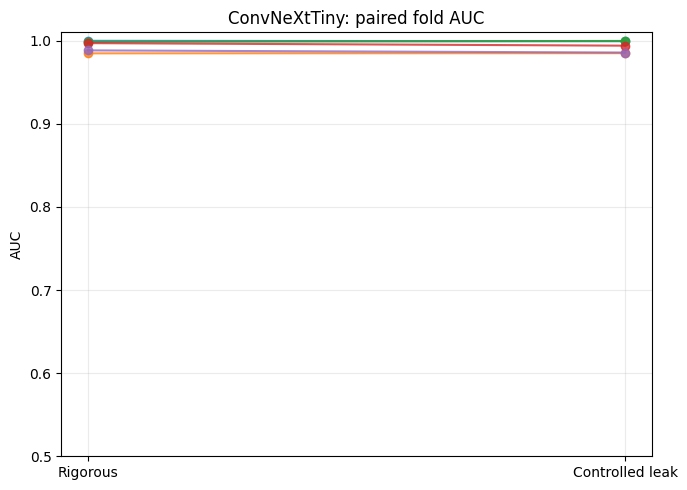

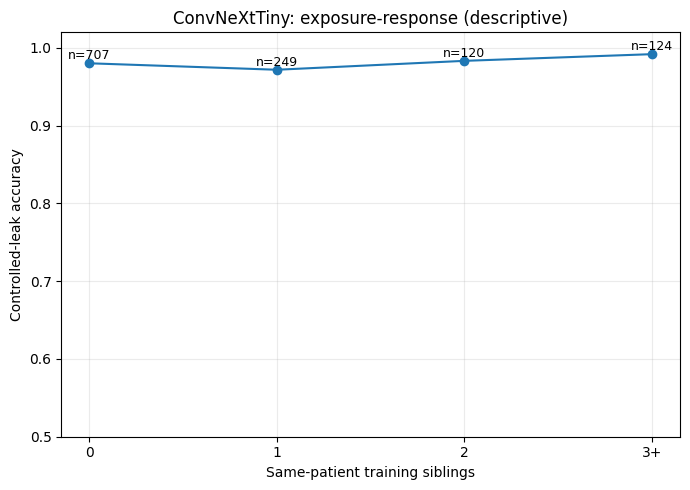

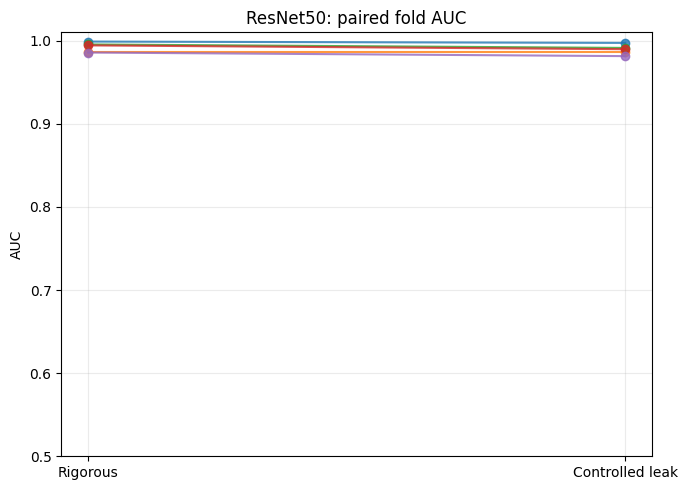

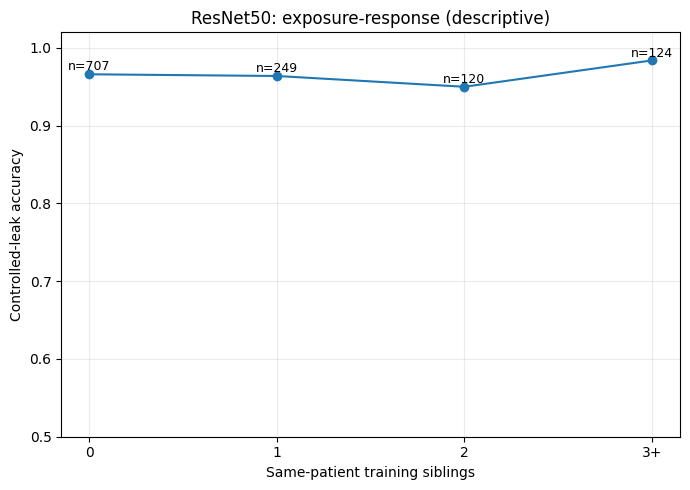

Figures saved -> /kaggle/working/oct_corrected_leakage_audit/figures


In [12]:
# =========================
# 12. Publication-ready diagnostic figures (not used for inference)
# =========================
for arch,d in oof.groupby('architecture'):
    # Fold-level AUC paired plot
    frows=[]
    for fold,g in d.groupby('fold'):
        frows.append((fold,metric_from_arrays(g.Label,g.prob_rig,'AUC'),metric_from_arrays(g.Label,g.prob_leak,'AUC')))
    ff=pd.DataFrame(frows,columns=['fold','rig','leak'])
    fig,ax=plt.subplots(figsize=(7,5))
    for _,r in ff.iterrows(): ax.plot(['Rigorous','Controlled leak'],[r.rig,r.leak],marker='o',alpha=.8)
    ax.set_ylabel('AUC'); ax.set_title(f'{arch}: paired fold AUC'); ax.set_ylim(0.5,1.01); ax.grid(alpha=.25)
    fig.tight_layout(); fig.savefig(FIG_DIR/f'{arch}_paired_fold_auc.png',dpi=250,bbox_inches='tight'); plt.show()

    # Exposure buckets
    z=d.copy(); z['correct']=(z.pred_leak==z.Label).astype(int)
    z['bucket']=pd.cut(z.n_train_siblings,bins=[-0.1,0.5,1.5,2.5,np.inf],labels=['0','1','2','3+'])
    b=z.groupby('bucket',observed=False).agg(n=('correct','size'),accuracy=('correct','mean')).reset_index()
    fig,ax=plt.subplots(figsize=(7,5)); ax.plot(b.bucket.astype(str),b.accuracy,marker='o')
    for i,r in b.iterrows():
        if np.isfinite(r.accuracy): ax.text(i,r.accuracy+0.005,f'n={int(r.n)}',ha='center',fontsize=9)
    ax.set_xlabel('Same-patient training siblings'); ax.set_ylabel('Controlled-leak accuracy')
    ax.set_title(f'{arch}: exposure-response (descriptive)'); ax.set_ylim(0.5,1.02); ax.grid(alpha=.25)
    fig.tight_layout(); fig.savefig(FIG_DIR/f'{arch}_exposure_response.png',dpi=250,bbox_inches='tight'); plt.show()

print('Figures saved ->',FIG_DIR)


In [13]:
# =========================
# 13. Automatic integrity report + manuscript-ready result summary
# =========================
summary={
    'cohort_images':int(len(cohort)),
    'cohort_patients':int(cohort.Patient_ID.nunique()),
    'folds':int(FOLDS),
    'architectures':RUN_ARCHITECTURES,
    'all_exact_row_overlap_zero':bool((audit_df.rig_train_test_exact_overlap.eq(0)&audit_df.leak_train_test_exact_overlap.eq(0)).all()),
    'all_exact_hash_overlap_zero':bool((audit_df.rig_train_test_hash_overlap.eq(0)&audit_df.leak_train_test_hash_overlap.eq(0)).all()),
    'all_rigorous_patient_overlap_zero':bool(audit_df.rig_train_test_patient_overlap.eq(0).all()),
    'all_validation_test_patient_overlap_zero':bool(audit_df.val_test_patient_overlap.eq(0).all()),
    'all_train_sizes_matched':bool(audit_df.rig_train_n.eq(audit_df.leak_train_n).all()),
    'all_train_class_counts_matched':bool((audit_df.rig_class0.eq(audit_df.leak_class0)&audit_df.rig_class1.eq(audit_df.leak_class1)).all()),
    'mean_test_sibling_exposure_pct':float(100*audit_df.test_exposure_pct.mean()),
}
with open(OUT/'integrity_summary.json','w') as f: json.dump(summary,f,indent=2)

print('\n=== INTEGRITY SUMMARY ===')
print(json.dumps(summary,indent=2))

assert all([
    summary['all_exact_row_overlap_zero'], summary['all_exact_hash_overlap_zero'],
    summary['all_rigorous_patient_overlap_zero'], summary['all_validation_test_patient_overlap_zero'],
    summary['all_train_sizes_matched'], summary['all_train_class_counts_matched']
])

print('\n=== PRIMARY CLUSTER-AWARE RESULTS ===')
primary=stats[stats.Metric.isin(['AUC','PR_AUC','Macro_F1','ACC','Brier'])].copy()
print(primary[['Architecture','Metric','Rigorous','ControlledLeak','Delta_LeakMinusRig','Delta_CI_Lo','Delta_CI_Hi','ClusterRandomization_p']].to_string(index=False,float_format=lambda x:f'{x:.4f}'))

print('\nInterpretation rule:')
print('- If the delta CI crosses 0, report the paired OCT leakage effect as uncertain / near-null under this corrected design.')
print('- If the CI excludes 0, report the observed paired effect size and CI without claiming a universal task-saturation law.')
print('- Brier/LogLoss: negative leak-minus-rigorous deltas are better; all other listed metrics: positive deltas are better.')



=== INTEGRITY SUMMARY ===
{
  "cohort_images": 1200,
  "cohort_patients": 855,
  "folds": 5,
  "architectures": [
    "ResNet50",
    "ConvNeXtTiny"
  ],
  "all_exact_row_overlap_zero": true,
  "all_exact_hash_overlap_zero": true,
  "all_rigorous_patient_overlap_zero": true,
  "all_validation_test_patient_overlap_zero": true,
  "all_train_sizes_matched": true,
  "all_train_class_counts_matched": true,
  "mean_test_sibling_exposure_pct": 41.083333333333336
}

=== PRIMARY CLUSTER-AWARE RESULTS ===
Architecture   Metric  Rigorous  ControlledLeak  Delta_LeakMinusRig  Delta_CI_Lo  Delta_CI_Hi  ClusterRandomization_p
ConvNeXtTiny      AUC    0.9937          0.9927             -0.0009      -0.0031       0.0011                  0.5187
ConvNeXtTiny   PR_AUC    0.9940          0.9925             -0.0014      -0.0038       0.0002                  0.2814
ConvNeXtTiny      ACC    0.9808          0.9800             -0.0008      -0.0072       0.0050                  1.0000
ConvNeXtTiny Macro_F1    0

In [14]:
# =========================
# 14. Bundle all reproducibility outputs
# =========================
readme = (
    'OCT CORRECTED LEAKAGE AUDIT\n\n'
    + f'Cohort: {len(cohort)} images, {cohort.Patient_ID.nunique()} patients\n'
    + f'Architectures: {", ".join(RUN_ARCHITECTURES)}\n'
    + f'Folds: {FOLDS}\n\n'
    + 'Key files:\n- cohort_manifest.csv\n- leakage_audit_by_fold.csv\n- oof_paired_predictions.csv\n'
    + '- cluster_aware_metrics.csv\n- leakage_exposure_analysis.csv\n- patient_label_concordance.csv\n'
    + '- splits/fold*_*.csv\n- predictions/*\n- figures/*\n- integrity_summary.json\n\n'
    + 'The rigorous arm has zero train/test patient overlap. The controlled-leak arm has no exact test-image overlap but deliberately contains other images from some test patients. Training size and binary class counts are matched between arms by same-class swaps. Both arms use the same test images and the same safe validation set.\n'
)
(OUT/'README.txt').write_text(readme)

archive=BASE/'OCT_Corrected_Leakage_Audit_Results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file(): z.write(p,p.relative_to(BASE))
print('Results archive:',archive)
print('Notebook run complete.')


Results archive: /kaggle/working/OCT_Corrected_Leakage_Audit_Results.zip
Notebook run complete.
